In [1]:
import geopandas as gpd

In [2]:
import fiona

In [5]:
gdb_path = "Decoupage.gdb" 
layers = fiona.listlayers(gdb_path)
print(layers)

['Wilaya_2', 'Commune_2', 'Moughataa_2']


In [9]:
import geopandas as gpd

# Remember to use the correct spelling "Decoupage"
gdb_path = "Decoupage.gdb"

# Load the Moughataa layer
moughataa = gpd.read_file(gdb_path, layer='Moughataa_2')

# Look at the first few rows to see what the column names are
print(moughataa.tail(15))


      M      Moughataa      المقاطعة Champ  Shape_Length    Shape_Area  \
48  104         Wompou          ومبو    10  2.133350e+05  2.379029e+09   
49  111   Bir Moghrein  بير أم اقرين    11  1.970672e+06  1.072970e+11   
50  112        Fdeirik        افديرك    11  2.132356e+06  2.007412e+11   
51  113       Zoueratt       ازويرات    11  1.137344e+05  8.249005e+08   
52  121        Akjoujt        اكجوجت    12  7.256887e+05  1.526337e+10   
53  122      Bennechab         بنشاب    12  7.467723e+05  2.054860e+10   
54  131           Ksar          لكصر    13  1.121087e+05  3.050847e+08   
55  132  Tevragh Zeina     تفرغ زينه    13  1.065060e+05  3.735546e+08   
56  133         Sebkha        السبخة    13  1.764372e+04  1.758108e+07   
57  143        Teyaret         تيارت    14  3.579987e+04  6.205548e+07   
58  142      Dar Nairn    دار النعيم    14  3.355968e+04  4.767146e+07   
59  141     Toujounine        توجنين    14  5.586790e+04  1.335111e+08   
60  151        Elrnina       الميناء  

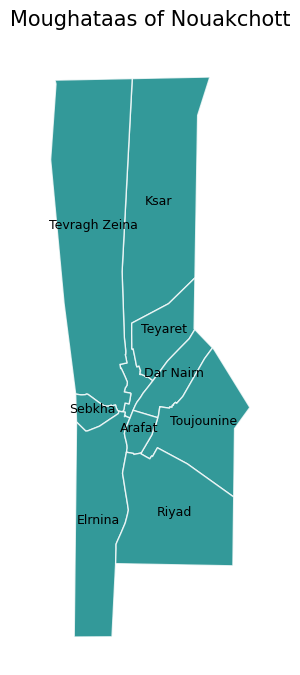

In [12]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Load the data
moughataa = gpd.read_file("Decoupage.gdb", layer='Moughataa_2')

# 2. Define the Nouakchott Moughataas
# I've included the 9 common ones
nkc_list = [
    'Tevragh Zeina', 'Ksar', 'Sebkha',          # Ouest
    'Dar Nairn', 'Teyaret', 'Toujounine',      # Nord
    'Arafat', 'Elrnina', 'Riyad'                # Sud
]

# 3. Filter the dataframe
# Using .isin() is the cleanest way to grab multiple specific names
nouakchott = moughataa[moughataa['Moughataa'].isin(nkc_list)]

# 4. Plot it
fig, ax = plt.subplots(figsize=(12, 8))
nouakchott.plot(ax=ax, color='teal', edgecolor='white', alpha=0.8)

# Add labels so you know which is which
for idx, row in nouakchott.iterrows():
    # Use the centroid of the geometry to place the text
    coords = row.geometry.centroid.coords[0]
    ax.annotate(text=row['Moughataa'], xy=coords, 
                horizontalalignment='center', fontsize=9, color='black')

plt.title("Moughataas of Nouakchott", fontsize=15)
ax.set_axis_off() # Hide lat/long coordinates for a cleaner look
plt.show()